# Getting Started with Anthive

Welcome! This interactive notebook will guide you through querying **single-cell RNA sequencing (scRNA-seq)** data using Anthive. No prior programming experience required - we'll explain everything step by step!

## What is Single-Cell RNA Sequencing?

**Single-cell RNA sequencing** measures gene expression in individual cells, rather than bulk tissue. This reveals cell-to-cell variation and identifies distinct cell types and states.

**Learn more:**
- [Introduction to scRNA-seq (Khan Academy)](https://www.khanacademy.org/science/biology/gene-expression-central-dogma)
- [Single-cell RNA-seq explained (Nature)](https://www.nature.com/articles/nmeth.4380)
- [Interactive scRNA-seq tutorial (10X Genomics)](https://www.10xgenomics.com/resources/analysis-guides)

---

## About This Environment

You're using **JupyterLite** - a complete data science environment running entirely in your web browser:

### What is Jupyter?
**Jupyter notebooks** let you combine code, text, and visualizations in one document. They're widely used in research and data science.

- **Code cells** (gray background) contain Python code that you can run
- **Markdown cells** (white background) contain formatted text and explanations
- **Run cells** by clicking them and pressing `Shift+Enter` or clicking the ▶️ button

**New to Jupyter?** Check these resources:
- [Jupyter Notebook Basics](https://jupyter-notebook.readthedocs.io/en/stable/notebook.html) - Official documentation
- [Getting Started with Jupyter](https://realpython.com/jupyter-notebook-introduction/) - Beginner tutorial
- [Jupyter Keyboard Shortcuts](https://towardsdatascience.com/jypyter-notebook-shortcuts-bf0101a98330) - Press `H` in command mode

### How JupyterLite Works
**JupyterLite** uses **Pyodide** to run Python in your browser:
- **No installation needed** - Everything runs locally in your browser
- **Your data stays private** - Nothing is uploaded to the cloud
- **Browser storage** - Your edits are saved automatically in your browser
- **Reset anytime** - Delete a notebook to restore the original version

**Important:** If you switch browsers or clear browser data, your saved work will be lost!

**Learn about Pyodide:**
- [Pyodide documentation](https://pyodide.org/) - Python in the browser
- [JupyterLite docs](https://jupyterlite.readthedocs.io/) - Browser-based Jupyter

---

## What is Anthive?

**Anthive** is a high-performance system for exploring single-cell RNA-seq data. Think of it as a search engine for gene expression across thousands or millions of cells.

### What can you do with Anthive?

- 🔍 **Find datasets** - Browse available scRNA-seq studies
- 🧬 **Search genes** - Look up expression of specific genes (e.g., *CD4*, *APOE*)
- 📊 **Get expression data** - Retrieve how much each gene is expressed in each cell
- 🏷️ **Filter by metadata** - Select cells by type (e.g., T cells, neurons), tissue, condition
- 📈 **Visualize patterns** - Create plots to explore gene expression patterns

### Why use Anthive?
Traditional scRNA-seq analysis requires downloading large files and complex software. Anthive lets you query data instantly through a simple Python interface - perfect for exploratory analysis and hypothesis generation!

**Learn more about scRNA-seq data:**
- [Single Cell Portal](https://singlecell.broadinstitute.org/) - Public scRNA-seq datasets
- [Scanpy tutorials](https://scanpy-tutorials.readthedocs.io/) - scRNA-seq analysis in Python
- [Cell type annotation resources](https://www.ebi.ac.uk/gxa/sc/home)

---

Let's get started with your first analysis!

## Setup: Install Required Python Packages

Before we start, we need to install some Python packages. Think of these as tools in a toolbox:

- **requests** - Communicates with the Anthive server to fetch data
- **pandas** - Handles data in tables (like Excel, but more powerful)
- **matplotlib** - Creates plots and visualizations
- **seaborn** - Makes beautiful statistical visualizations

**Note:** This first cell may take 30-60 seconds to run. Be patient!

**Learn more:**
- [Pandas tutorial](https://pandas.pydata.org/docs/getting_started/intro_tutorials/) - Working with data tables
- [Matplotlib gallery](https://matplotlib.org/stable/gallery/index.html) - Plot examples
- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html) - Statistical visualizations

In [1]:
import micropip
await micropip.install(['requests', 'pandas', 'matplotlib', 'seaborn'])
print("✓ Packages installed")

✓ Packages installed


## Step 1: Import Libraries and Connect to Anthive

Now we'll load the tools we need and connect to the Anthive server.

### What's happening in the code below?
1. **Import statements** - Load the Python libraries we need
2. **Create a client** - Establish connection to the Anthive API server
3. **Auto-detect URL** - Automatically find the correct server address

The `anthelper` module contains convenience functions to make your life easier (see `anthelper.py` for details).

**Python concepts:**
- `import` - Loads a library or module so you can use it
- Variables (like `client`) - Store information for later use
- Functions (like `AnthiveClient()`) - Perform actions or calculations

**Learn more:**
- [Python for beginners](https://www.python.org/about/gettingstarted/) - Official Python tutorial
- [Variables in Python](https://realpython.com/python-variables/) - Understanding variables
- [What is an API?](https://www.howtogeek.com/343877/what-is-an-api/) - API basics explained

In [2]:
# helper for development
%reload_ext autoreload
%autoreload 1
%aimport anthelper

In [48]:
from antclient import AnthiveClient

import pandas as pd
import textwrap
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

# Create client - get current origin from browser
try:
    import js
    api_url = f"{js.location.origin}/api"
except:
    api_url = None  # Will auto-detect

client = AnthiveClient(api_url)
print(f"✓ Connected to {client.base_url}")

✓ Connected to http://localhost:8501/api


## Step 2: Browse Available Datasets

Let's see what scRNA-seq datasets are available in Anthive. Each dataset typically represents:
- A published study or experiment
- Cells from specific tissues, organisms, or conditions
- Processed gene expression data

### Understanding the output:
- **id** - Unique identifier (format: `Author/StudyName`)
- **title** - Human-readable name
- **n_cells** - Number of cells sequenced (thousands to millions!)
- **n_genes** - Number of genes measured (typically 20,000-30,000 for human/mouse)

### What is a DataFrame?
A **DataFrame** is like a spreadsheet in Python - it has rows and columns and lets you easily filter, sort, and analyze data.

**Learn more:**
- [What is gene expression?](https://www.genome.gov/genetics-glossary/Gene-Expression) - NIH explainer
- [scRNA-seq data structure](https://nbisweden.github.io/workshop-scRNAseq/exercises/compiled/scanpy/scanpy_01_qc.html) - Understanding cell x gene matrices

In [4]:
# Get list of databases as a DataFrame
databases = client.get_databases(format='dataframe')

print(f"Found {len(databases)} database(s)")
print()

# Show key info
databases[['id', 'title', 'n_cells', 'n_genes']].head()

Found 11 database(s)



,id,title,n_cells,n_genes
0,Blackburn2026/seurat_obj_final,seurat_obj_final,73888,29694
1,Blackburn2026/seurat_obj_trisomy_initial,seurat_obj_trisomy_initial,88582,29694
2,Lloyd2024/Lloyd.proteomics.human,Lloyd.proteomics.human,11,9437
3,Lloyd2024/Lloyd.proteomics.human_mouse,Lloyd.proteomics.human_mouse,21,10737
4,Lloyd2024/Lloyd.proteomics.mouse,Lloyd.proteomics.mouse,10,9669


### Using the Helper Function

The `anthelper` module provides shortcuts for common tasks. The `find_database()` function lets you search for datasets by name:

```python
anthelper.find_database(client, 'searchterm')
```

This is easier than manually filtering the DataFrame! Try searching for different terms like author names, tissues, or species.

In [15]:
anthelper.find_database(client, 'Blackburn')

,id,title,n_cells,n_genes
0,Blackburn2026/seurat_obj_final,seurat_obj_final,73888,29694
1,Blackburn2026/seurat_obj_trisomy_initial,seurat_obj_trisomy_initial,88582,29694


## Step 3: Select a Dataset and Explore Its Contents

Now let's pick one dataset to work with and see what's inside.

### Understanding scRNA-seq Data Layers

Single-cell data typically has multiple "layers" representing different processing stages:

- **counts** (or **X**) - Raw counts: How many RNA molecules detected per gene
- **data** - Normalized: Adjusted for cell size and sequencing depth  
- **scaled** - Z-scored: Standardized for statistical comparison

Most analyses use the **normalized** layer ("data") because it accounts for technical variation.

### What are embeddings?

**Embeddings** (like UMAP, t-SNE, PCA) are 2D/3D projections that let you visualize high-dimensional data (thousands of genes → 2 dimensions). They help identify cell clusters and patterns.

**Learn more:**
- [Normalization in scRNA-seq](https://www.sc-best-practices.org/preprocessing_visualization/normalization.html) - Why normalize?
- [UMAP explained](https://pair-code.github.io/understanding-umap/) - Interactive visualization tutorial
- [Understanding t-SNE](https://distill.pub/2016/misread-tsne/) - Common pitfalls

In [18]:
# Use first database (or replace with any database you like:
db_id = databases.iloc[0]['id']
print(f"Selected database: {db_id}")
print()

# Get database info
info = client.get_database_info(db_id)
print(f"Cells: {info['n_cells']:,}")
print(f"Genes: {info['n_genes']:,}")
print(f"Available layers: {', '.join(info['layers']) if info['layers'] else 'None'}")
print(f"Available embeddings: {', '.join(info['embeddings']) if info['embeddings'] else 'None'}")

# Determine which layer to use (prefer "X", fallback to first available)
if 'X' in info['layers']:
    layer = 'X'
elif info['layers']:
    layer = info['layers'][0]
else:
    layer = 'ERROR!'
    print("Warning: Cannot find a proper layer??")

print(f"\nUsing layer: {layer}")

Selected database: Blackburn2026/seurat_obj_final

Cells: 73,888
Genes: 29,694
Available layers: counts, data
Available embeddings: None

Using layer: counts


## Step 4: Search for Genes of Interest

Let's find genes to analyze! Gene names follow standard nomenclature:
- Human genes: ALL CAPS (e.g., *APOE*, *CD4*, *BRCA1*)
- Mouse genes: First letter caps (e.g., *Apoe*, *Cd4*, *Brca1*)

### How gene search works:
The search finds any gene containing your search string (case-insensitive):
- Search "CD" → finds *CD4*, *CD8A*, *CD19*, etc.
- Search "APOE" → finds *APOE*, *APOER2*, etc.

### Finding the right genes:
Not sure what gene to search for? Try:
- **Disease/pathway** - "ALZH", "PARKIN", "APOE" (Alzheimer's)
- **Cell markers** - "CD" (immune cells), "GFAP" (astrocytes)
- **Function** - "TREM" (immune signaling), "SYN" (synapses)

**Useful resources:**
- [GeneCards](https://www.genecards.org/) - Comprehensive gene database
- [HUGO Gene Nomenclature](https://www.genenames.org/) - Official gene names
- [CellMarker](http://bio-bigdata.hrbmu.edu.cn/CellMarker/) - Cell type markers
- [UniProt](https://www.uniprot.org/) - Protein function database

In [32]:
# Search for genes containing "CD"
genes = client.search_genes(db_id, q="APO", limit=50)
print(f"Found genes: {', '.join(genes)}")

Found genes: APOA1, APOA1-AS, APOA2, APOBEC1, APOBEC2, APOBEC3A, APOBEC3B, APOBEC3C, APOBEC3D, APOBEC3F, APOBEC3G, APOBEC3H, APOBEC4, APOBR, APOC1, APOC1P1, APOC2, APOC4, APOD, APOE, APOF, APOH, APOL1, APOL2, APOL3, APOL4, APOL6, APOLD1, APOM, APOO, APOOL, ELAPOR1, ELAPOR2, PAPOLA, PAPOLA-DT, PAPOLG


## Step 5: Retrieve Gene Expression Data

Now the fun part - let's get actual gene expression values! This creates a table where:
- Each **row** is a cell
- Each **column** is a gene  
- Each **value** is expression level (higher = more RNA detected)

### Understanding expression values:
- **0** = Gene not detected (cell doesn't express it)
- **Low values (1-3)** = Weak expression
- **Medium (3-6)** = Moderate expression  
- **High (>6)** = Strong expression

These are typically **log-transformed** values, so small differences represent big changes!

### What genes should you query?
Choose genes relevant to your research question:
- **Cell type markers** - Identify what cells you're looking at
- **Disease genes** - Genes associated with your condition of interest
- **Pathway members** - Genes working together in biological processes

**Tip:** Start with 3-5 genes to keep results manageable.

**Learn more:**
- [Understanding gene expression levels](https://www.ebi.ac.uk/gxa/sc/home) - Expression Atlas
- [Log transformation explained](https://www.nature.com/articles/nmeth.4292) - Why log scale?
- [Interpreting scRNA-seq data](https://www.sc-best-practices.org/introduction/analysis_tools.html) - Analysis guide

In [75]:
# replace with genes of interest:
query_genes = ['APOE', 'MALAT1', 'TREM2', 'HLA-DRA']

# get expression data
df = client.get_cells(
    db_id,
    genes=query_genes,
    layer='data',  # Use detected layer
    format='dataframe'
)

print(f"Retrieved {len(df)} cells")
print(f"Columns: {', '.join(df.columns)}")
print()
df.head()

Retrieved 73888 cells
Columns: cell_name, APOE, MALAT1, TREM2, HLA-DRA



,cell_name,APOE,MALAT1,TREM2,HLA-DRA
0,BDAG185.1H_TCACACCCACCTACCG-1,3.688412,6.343577,0.832638,0.832638
1,BDAG185.1H_TCACACCCACCTATAT-1,4.078200,5.873393,1.876029,0.000000
2,BDAG185.1H_TCACACCCATCGCTCG-1,2.963748,5.876396,2.147602,0.000000
3,BDAG185.1H_TCACAGGCAAGCCAGC-1,3.546203,5.964757,1.703083,0.000000
4,BDAG185.1H_TCACAGGCATCCTAAT-1,2.845954,5.233814,1.769069,0.000000


## Step 6: Visualize Gene Expression

Let's create a **scatter plot** to explore the relationship between two genes.

### What does the plot show?
- Each **point** is one cell
- **X-axis** = Expression of first gene
- **Y-axis** = Expression of second gene
- **Patterns** reveal biological insights:
  - **Diagonal line** = Genes co-expressed (often same pathway)
  - **Two clusters** = Different cell types
  - **L-shape** = Mutually exclusive (genes mark different cells)

### Interpreting your plot:
- **Dense bottom-left** = Many cells don't express either gene
- **Spread** = High cell-to-cell variability
- **Clusters** = Distinct cell populations

**Try this:** Change `gene1` and `gene2` to explore different gene pairs!

**Learn more:**
- [Scatter plot interpretation](https://www.data-to-viz.com/graph/scatter.html) - Visual guide
- [Gene co-expression](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6082223/) - What it means
- [Matplotlib tutorial](https://matplotlib.org/stable/tutorials/introductory/pyplot.html) - Creating plots

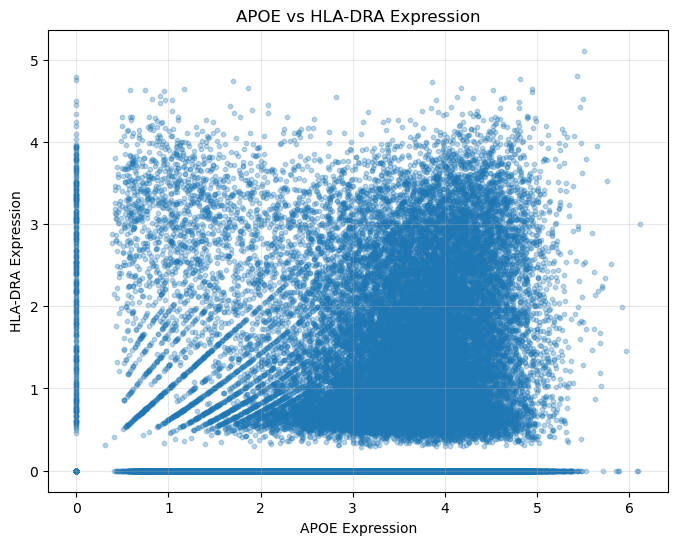

In [77]:

# genes just selected
gene1 = query_genes[0]
gene2 = query_genes[3]

# Scatter plot of gene1 vs gene2
plt.figure(figsize=(8, 6))
plt.scatter(df[gene1], df[gene2], alpha=0.3, s=10)
plt.xlabel(f'{gene1} Expression')
plt.ylabel(f'{gene2} Expression')
plt.title(f'{gene1} vs {gene2} Expression')
plt.grid(True, alpha=0.3)
plt.show()

## Step 7: Add Cell Metadata for Context

**Metadata** = Information *about* each cell (beyond gene expression). This lets you:
- Group cells by type, tissue, condition
- Compare expression across experimental groups
- Filter for cells of interest

### Common metadata fields:
**Biological:**
- `cell_type` - What kind of cell (neuron, T cell, etc.)
- `tissue` - Anatomical location
- `donor`/`sample` - Which individual/sample

**Technical:**
- `nCount_RNA` - Total RNA molecules detected (quality metric)
- `percent.mt` - % mitochondrial genes (stress indicator)
- `batch` - Which experimental batch (technical variation)

**Experimental:**
- `condition` - Treatment, disease status, etc.
- `group_id` - Experimental groups for comparison
- `genotype` - Genetic background

### Finding available metadata:
The code below shows which metadata fields are available for your dataset. Fields vary by study!

**Learn more:**
- [Single-cell metadata standards](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC10653056/) - Best practices
- [Cell Ontology](http://www.obofoundry.org/ontology/cl.html) - Standardized cell type names
- [Quality control in scRNA-seq](https://www.sc-best-practices.org/preprocessing_visualization/quality_control.html) - QC metrics explained

In [78]:
# you can use the raw call:
print(client.get_metadata_fields(db_id))

{'numerical': ['nCount_RNA', 'nFeature_RNA', 'pool_id', 'human_frac', 'mouse_frac', 'scDblFinder.score', 'scDblFinder.weighted', 'percent.mt', 'median_count', 'mad_count', 'upper_limit_5_mad', 'upper_limit_3_mad', 'nCount_SCT', 'nFeature_SCT', 'dendritic1', 'proliferating2', 'macrophage3', 'myeloid4', 'CRM5', 'DAM6', 'HLA7', 'HM8', 'IRM9', 'RM10', 'tCRM11'], 'categorical': ['orig.ident', 'processing_batch', 'SAMPLE', 'app_genotype', 'sample_hash', 'microglia', 'sex', 'group_id', 'species_call', 'scDblFinder.class', 'mad5_outlier', 'mad3_outlier', 'outlier_status', 'SCT_snn_res.0.2', 'seurat_clusters', 'rpca_clusters']}


In [ ]:
### Using the Helper Function

The `anthelper.find_metadata()` function formats the output nicely and lets you search for specific fields:

```python
# Show all metadata
anthelper.find_metadata(client, db_id)

# Search for specific fields
anthelper.find_metadata(client, db_id, "cell")  # Find cell-related fields
anthelper.find_metadata(client, db_id, "count")  # Find count metrics
```

**Tip:** Different datasets have different metadata! Always check what's available before querying.

In [ ]:
# Get expression data WITH metadata
# Note: We're querying the 'data' layer (normalized counts)
df_meta = client.get_cells(
    db_id,
    genes=query_genes,  # Same genes as before
    metadata=["group_id"],  # Add metadata column(s) - change as needed!
    layer=layer,
    format='dataframe'
)

print(f"Retrieved {len(df_meta)} cells with metadata")
print(f"Columns: {', '.join(df_meta.columns)}")
print()
df_meta.head()

# Now your DataFrame has both gene expression AND metadata!

In [ ]:
# Create a boxplot to compare expression across groups
# This shows the distribution of gene expression in each group

sns.boxplot(data=df_meta, x='group_id', y='HLA-DRA')
plt.ylim(0, 5)  # Focus on the interesting range
plt.ylabel('HLA-DRA Expression (log)')
plt.xlabel('Experimental Group')
plt.title('HLA-DRA Expression by Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Boxplot interpretation:
# - Box = middle 50% of cells (25th-75th percentile)
# - Line in box = median
# - Whiskers = range of most data
# - Dots = outliers (cells with unusual expression)

## Step 8: Group by Cell Type

Calculate mean expression per cell type.

In [84]:
# Check if we have cell_type data
if 'cell_type' in df_meta.columns:
    # Group by cell_type and calculate mean
    grouped = df_meta.groupby('cell_type')[['CD4', 'CD8A']].mean()
    
    print("Mean expression by cell type:")
    print(grouped)
    
    # Bar plot
    grouped.plot(kind='bar', figsize=(10, 6))
    plt.ylabel('Mean Expression')
    plt.title('CD4 and CD8A Expression by Cell Type')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No cell_type metadata available for this database")

No cell_type metadata available for this database


## Optional: Install Additional Packages

If you need additional analysis packages like seaborn or scikit-learn, install them with micropip:

In [87]:
# install additional packages
# await micropip.install(['seaborn', 'scikit-learn', 'scipy'])
# import seaborn as sns

## Next Steps and Resources

Congratulations! You've learned the basics of querying scRNA-seq data with Anthive. Here's what to try next:

### Explore Further

1. **Try different genes** - Search for genes relevant to your research
2. **Compare groups** - Use metadata to compare conditions, cell types, or treatments
3. **Advanced filtering** - See `Anthive_Example.ipynb` for filtering cells by expression levels
4. **Multiple genes** - Query 10-20 genes to build a gene expression signature
5. **Statistical testing** - Use Python stats libraries to find significant differences

### Additional Analysis Ideas

**Cell type identification:**
```python
# Query known marker genes for different cell types
markers = client.get_cells(db_id, 
                          genes=["CD3E", "CD14", "GFAP", "NES"],  # T cells, monocytes, astrocytes, neural stem
                          metadata=["cell_type"], 
                          format='dataframe')
```

**Compare experimental conditions:**
```python
# Compare gene expression between conditions
df = client.get_cells(db_id,
                     genes=["your_gene"],
                     metadata=["condition", "group_id"],
                     format='dataframe')
# Then use seaborn for visualization
sns.violinplot(data=df, x='condition', y='your_gene')
```

**Correlation analysis:**
```python
# Find genes that co-vary
df = client.get_cells(db_id, genes=["GENE1", "GENE2", "GENE3"], format='dataframe')
df.corr()  # Pearson correlation matrix
```

---

### Quick Reference

```python
# List databases
databases = client.get_databases(format='dataframe')
anthelper.find_database(client, "search_term")

# Get database info and detect layer
info = client.get_database_info(db_id)
layer = 'data' if 'data' in info['layers'] else info['layers'][0]

# Find available metadata
anthelper.find_metadata(client, db_id)
anthelper.find_metadata(client, db_id, "search_term")

# Search genes
genes = client.search_genes(db_id, q="CD4", limit=50)

# Get expression data
df = client.get_cells(db_id, 
                     genes=["CD4", "CD8A"], 
                     metadata=["cell_type"],
                     layer=layer, 
                     limit=10000,
                     format='dataframe')

# Get embeddings (if available)
umap_df = client.get_embedding_data(db_id, "Umap", n_dims=2, format='dataframe')

# Advanced: SQL query
df = client.execute_sql(db_id, "SELECT * FROM obscat LIMIT 100", format='dataframe')
```

---

### Learning Resources

**Single-cell RNA-seq:**
- [Orchestrating Single-Cell Analysis with Bioconductor](https://bioconductor.org/books/release/OSCA/) - Free textbook
- [Single-cell best practices](https://www.sc-best-practices.org/) - Comprehensive guide
- [Scanpy tutorials](https://scanpy-tutorials.readthedocs.io/) - Python workflows
- [Seurat tutorials](https://satijalab.org/seurat/articles/get_started.html) - R workflows

**Python for biology:**
- [Python for Biologists](https://pythonforbiologists.com/) - Beginner-friendly
- [Rosalind](http://rosalind.info/) - Learn bioinformatics through problems
- [Biopython tutorial](https://biopython.org/wiki/Documentation) - Bioinformatics in Python

**Data visualization:**
- [From Data to Viz](https://www.data-to-viz.com/) - Choose the right chart
- [Seaborn gallery](https://seaborn.pydata.org/examples/index.html) - Beautiful plots
- [Matplotlib cheatsheets](https://matplotlib.org/cheatsheets/) - Quick reference

**Statistics:**
- [StatQuest videos](https://www.youtube.com/c/joshstarmer) - Statistics explained clearly
- [Seeing Theory](https://seeing-theory.brown.edu/) - Visual statistics intro

---

### Need Help?

- **Anthive Example notebook** - More advanced usage examples
- **anthelper.py documentation** - Helper function details  
- **Anthive documentation** - Full API reference (coming soon)

Happy exploring! 🧬📊